# 01 — Inventario y demografía del dataset Leipzig Heart Center

**Etapa I (PPS) / F2.** Consume las tablas generadas por `scripts/inventario.py` (F1):
`results/inventario/registros.csv`. Objetivo: caracterizar la población (edad, sexo,
diagnósticos) y las grabaciones (duración, canales) que alimentarán el diseño del pipeline.

In [1]:
%matplotlib inline
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path(os.environ.get('PROJECT_ROOT',
                           Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()))
RES = ROOT / 'results'
FIG = RES / 'figuras'
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
rng = np.random.default_rng(2026)

registros = pd.read_csv(RES / 'inventario' / 'registros.csv')
registros.head(3)


,registro,grupo,edad_anos,sexo,diagnostico,fs_hz,duracion_min,n_canales,n_deriv_superf,anot_calidad
0,x001,pediatrico,6.6,M,AVRT,977,145.49,19,12,48
1,x002,pediatrico,11.0,M,AVNRT,977,105.30,18,12,42
2,x003,pediatrico,11.9,F,AVRT-WPW,977,150.53,19,12,58


In [2]:
resumen = registros.groupby('grupo').agg(
    n=('registro', 'count'),
    edad_min=('edad_anos', 'min'), edad_mediana=('edad_anos', 'median'), edad_max=('edad_anos', 'max'),
    dur_total_min=('duracion_min', 'sum'), dur_mediana_min=('duracion_min', 'median'),
    anot_calidad=('anot_calidad', 'sum'),
).round(2)
resumen


,n,edad_min,edad_mediana,edad_max,dur_total_min,dur_mediana_min,anot_calidad
grupo,,,,,,,
adulto,10,21.68,46.38,64.16,236.90,19.43,2
pediatrico,29,5.00,12.50,18.10,870.09,8.39,226


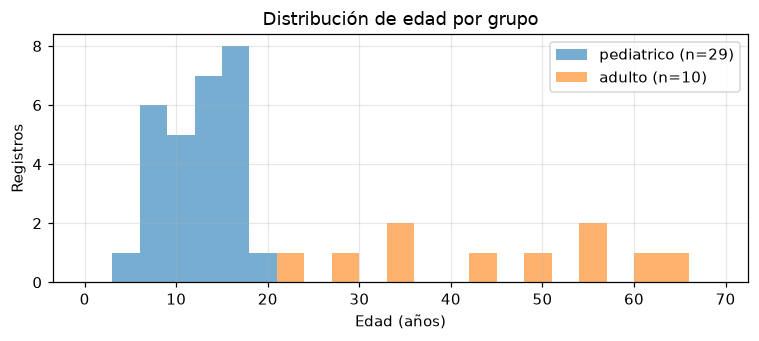

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for grupo, color in [('pediatrico', 'tab:blue'), ('adulto', 'tab:orange')]:
    edades = registros.loc[registros.grupo == grupo, 'edad_anos']
    ax.hist(edades, bins=np.arange(0, 70, 3), alpha=0.6, label=f'{grupo} (n={len(edades)})', color=color)
ax.set_xlabel('Edad (años)'); ax.set_ylabel('Registros')
ax.set_title('Distribución de edad por grupo')
ax.legend()
fig.tight_layout(); fig.savefig(FIG / '01_edad_por_grupo.png'); plt.show()


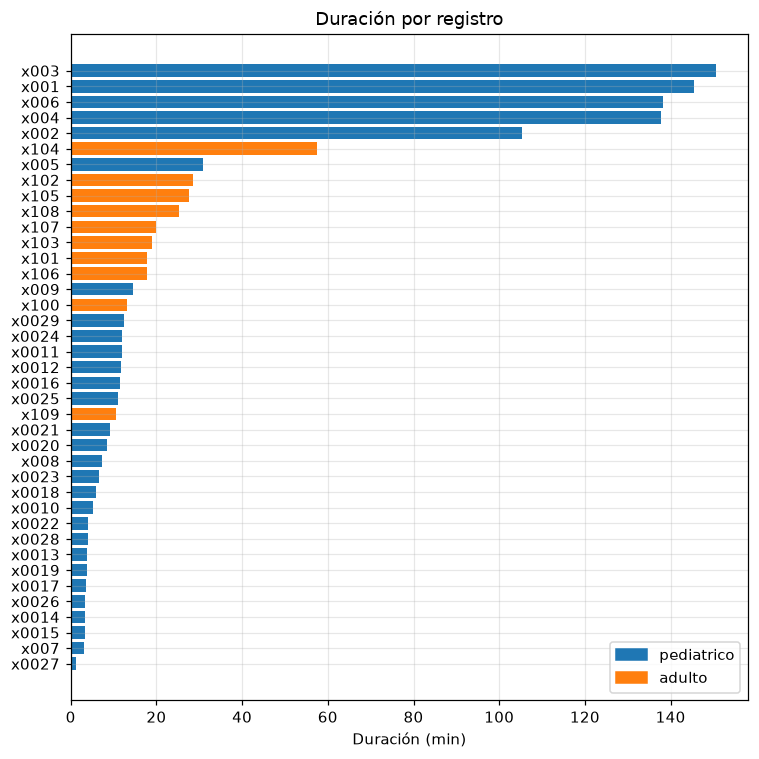

In [4]:
ord_ = registros.sort_values('duracion_min')
fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(ord_.registro, ord_.duracion_min, color=ord_.grupo.map({'pediatrico': 'tab:blue', 'adulto': 'tab:orange'}))
ax.set_xlabel('Duración (min)'); ax.set_title('Duración por registro')
import matplotlib.patches as mp
ax.legend(handles=[mp.Patch(color='tab:blue', label='pediatrico'), mp.Patch(color='tab:orange', label='adulto')])
fig.tight_layout(); fig.savefig(FIG / '01_duracion_por_registro.png'); plt.show()


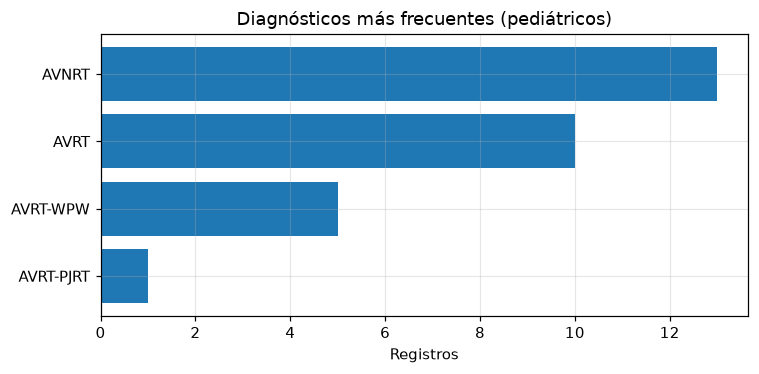

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ped = registros[registros.grupo == 'pediatrico']
dx = pd.DataFrame({'diagnostico': pd.concat([ped.diagnostico, ped.diagnostico]).value_counts().head(12)})
dx = ped.diagnostico.value_counts().head(12)
ax.barh(dx.index[::-1], dx.values[::-1], color='tab:blue')
ax.set_xlabel('Registros'); ax.set_title('Diagnósticos más frecuentes (pediátricos)')
fig.tight_layout(); fig.savefig(FIG / '01_diagnosticos_ped.png'); plt.show()


## Conclusiones

- 29 registros pediátricos + 10 adultos; todos a 977 Hz y con las 12 derivaciones superficiales.
- La población pediátrica cubre un rango etario amplio (ver histograma): relevante porque la
  morphología ECG normal *depende de la edad* en pediatría (criterios de QRS/RR distintos).
- Los diagnósticos dominantes definen qué arritmias son representables (insumo de AP-1).